Columnas encontradas:
['MaxP', 'MaxQ', 'Activo', 'Rentabilidad (%)', 'Beneficio Neto', 'Max equity drawdown (%)']


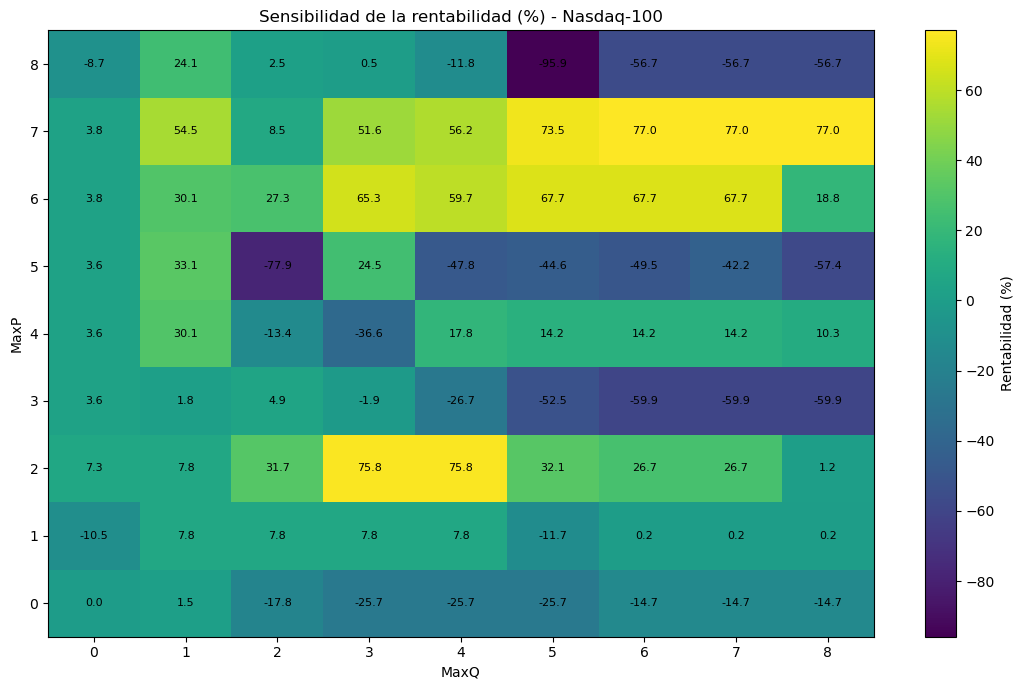

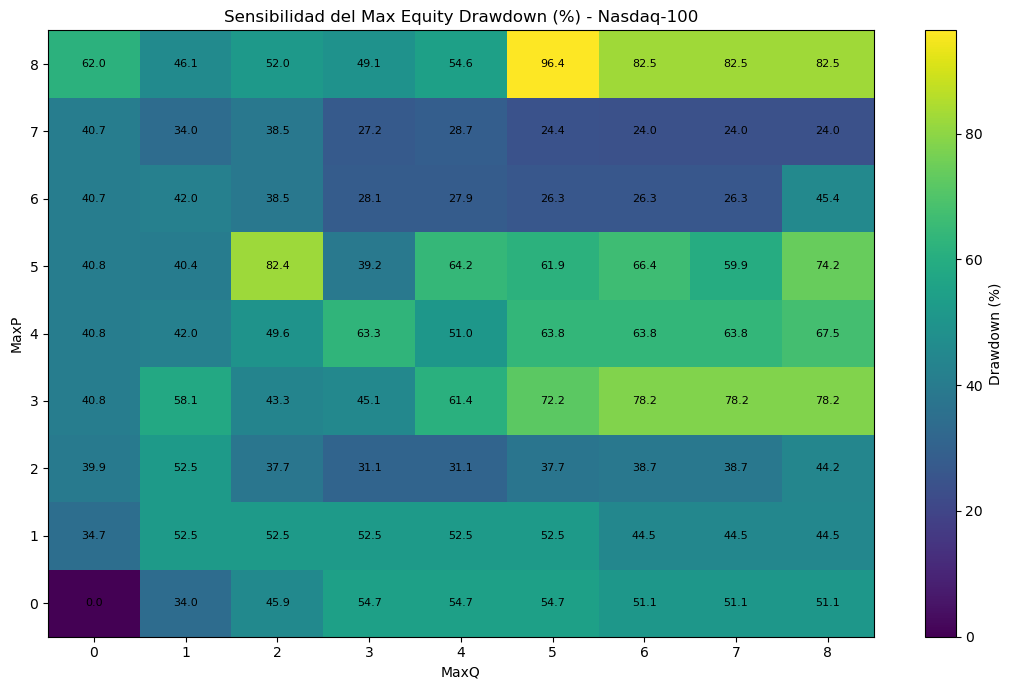

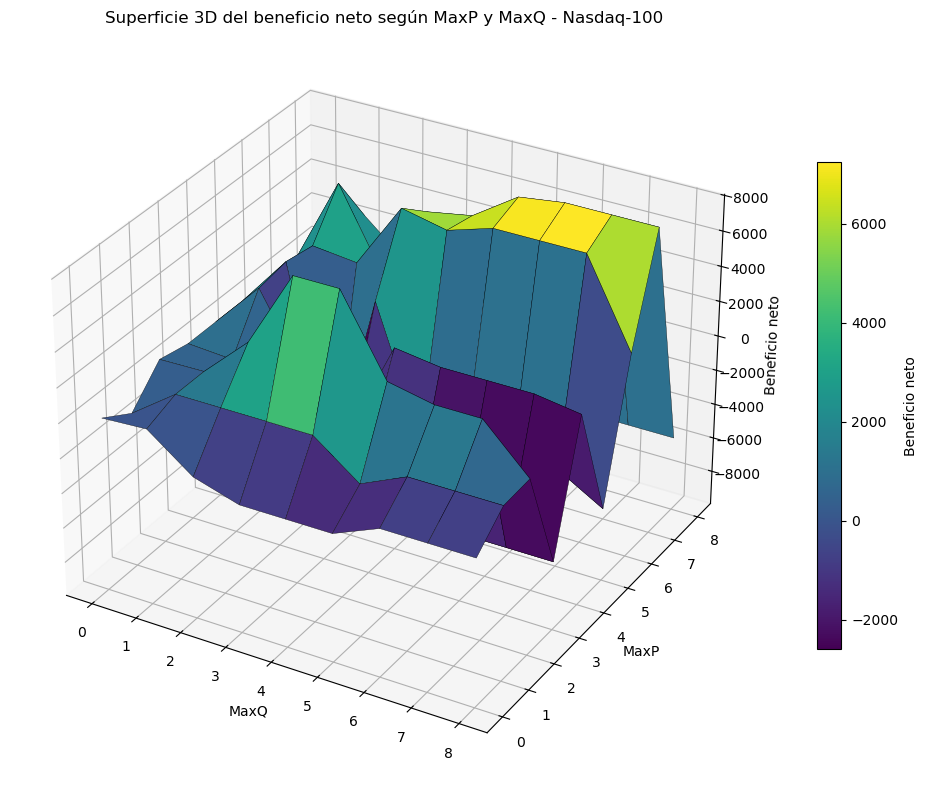

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

archivo = "Resultados.xlsx"  # Cambia por el nombre de tu archivo
hoja = 0                     # Primera hoja del Excel

df = pd.read_excel(archivo, sheet_name=hoja)

# Limpiar nombres de columnas y espacios repetidos
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("Columnas encontradas:")
print(df.columns.tolist())

# Verificar que existan las columnas necesarias
columnas = [
    "MaxP",
    "MaxQ",
    "Rentabilidad (%)",
    "Beneficio Neto",
    "Max equity drawdown (%)",
]

faltantes = [c for c in columnas if c not in df.columns]

if faltantes:
    raise ValueError(
        f"Faltan estas columnas en el Excel: {faltantes}"
    )

# Convertir las variables a formato numérico
def convertir_numero(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(serie, errors="coerce")

    s = serie.astype(str).str.strip()
    s = s.str.replace("%", "", regex=False)
    s = s.str.replace(" ", "", regex=False)

    # Admite formatos como 1.234,56 y 1234,56
    formato_espanol = s.str.contains(",", regex=False)

    s.loc[formato_espanol] = (
        s.loc[formato_espanol]
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )

    return pd.to_numeric(s, errors="coerce")


for col in columnas:
    df[col] = convertir_numero(df[col])



# Crear matrices MaxP x MaxQ
roi = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Rentabilidad (%)", aggfunc="mean"
).sort_index().sort_index(axis=1)

drawdown = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Max equity drawdown (%)", aggfunc="mean"
).reindex(index=roi.index, columns=roi.columns)

beneficio = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Beneficio Neto", aggfunc="mean"
).reindex(index=roi.index, columns=roi.columns)

# ============================================================
# 2. GRÁFICO 1: MAPA DE CALOR DE RENTABILIDAD
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

im = ax.imshow(
    roi.to_numpy(),
    aspect="auto",
    origin="lower"
)

ax.set_xticks(range(len(roi.columns)))
ax.set_xticklabels(roi.columns)
ax.set_yticks(range(len(roi.index)))
ax.set_yticklabels(roi.index)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_title("Sensibilidad de la rentabilidad (%) - Nasdaq-100")

for i in range(len(roi.index)):
    for j in range(len(roi.columns)):
        valor = roi.iloc[i, j]
        if pd.notna(valor):
            ax.text(
                j, i, f"{valor:.1f}",
                ha="center", va="center", fontsize=8
            )

fig.colorbar(im, ax=ax, label="Rentabilidad (%)")
plt.tight_layout()
plt.show()

# ============================================================
# 3. GRÁFICO 2: MAPA DE CALOR DEL DRAWDOWN
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

im = ax.imshow(
    drawdown.to_numpy(),
    aspect="auto",
    origin="lower"
)

ax.set_xticks(range(len(drawdown.columns)))
ax.set_xticklabels(drawdown.columns)
ax.set_yticks(range(len(drawdown.index)))
ax.set_yticklabels(drawdown.index)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_title("Sensibilidad del Max Equity Drawdown (%) - Nasdaq-100")

for i in range(len(drawdown.index)):
    for j in range(len(drawdown.columns)):
        valor = drawdown.iloc[i, j]
        if pd.notna(valor):
            ax.text(
                j, i, f"{valor:.1f}",
                ha="center", va="center", fontsize=8
            )

fig.colorbar(im, ax=ax, label="Drawdown (%)")
plt.tight_layout()
plt.show()

# ============================================================
# 5. GRÁFICO 4: SUPERFICIE 3D DEL BENEFICIO NETO
# ============================================================

from mpl_toolkits.mplot3d import Axes3D

X, Y = np.meshgrid(
    beneficio.columns.to_numpy(dtype=float),
    beneficio.index.to_numpy(dtype=float)
)

Z = beneficio.to_numpy(dtype=float)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.25,
    antialiased=True
)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_zlabel("Beneficio neto")
ax.set_title("Superficie 3D del beneficio neto según MaxP y MaxQ - Nasdaq-100")

fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    label="Beneficio neto"
)

plt.tight_layout()
plt.show()


Columnas encontradas:
['MaxP', 'MaxQ', 'Activo', 'Rentabilidad (%)', 'Beneficio Neto', 'Max equity drawdown (%)']


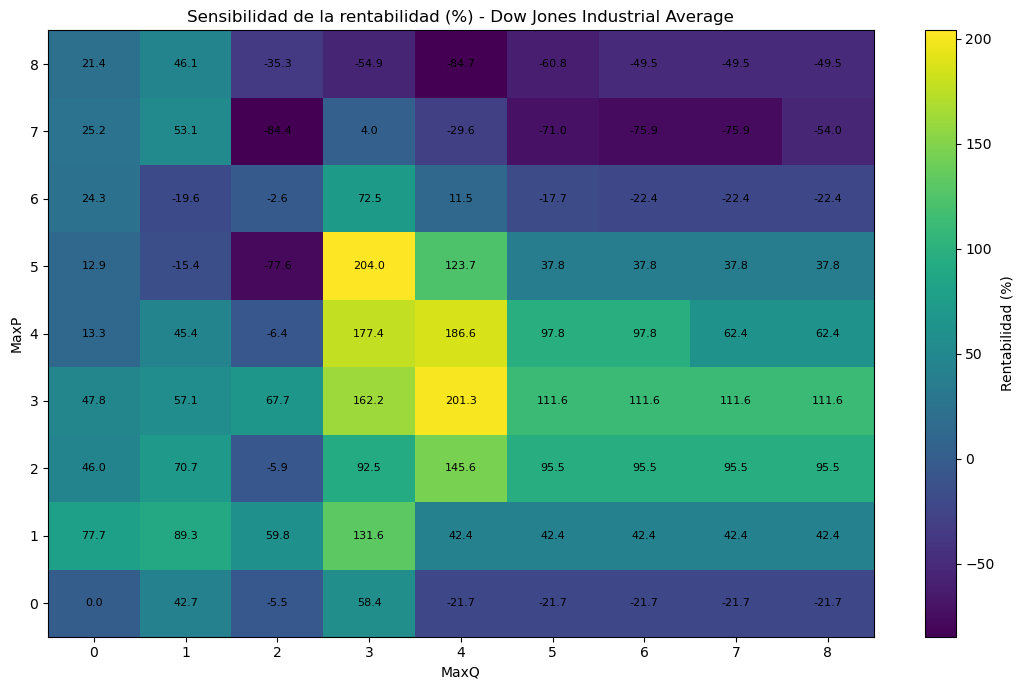

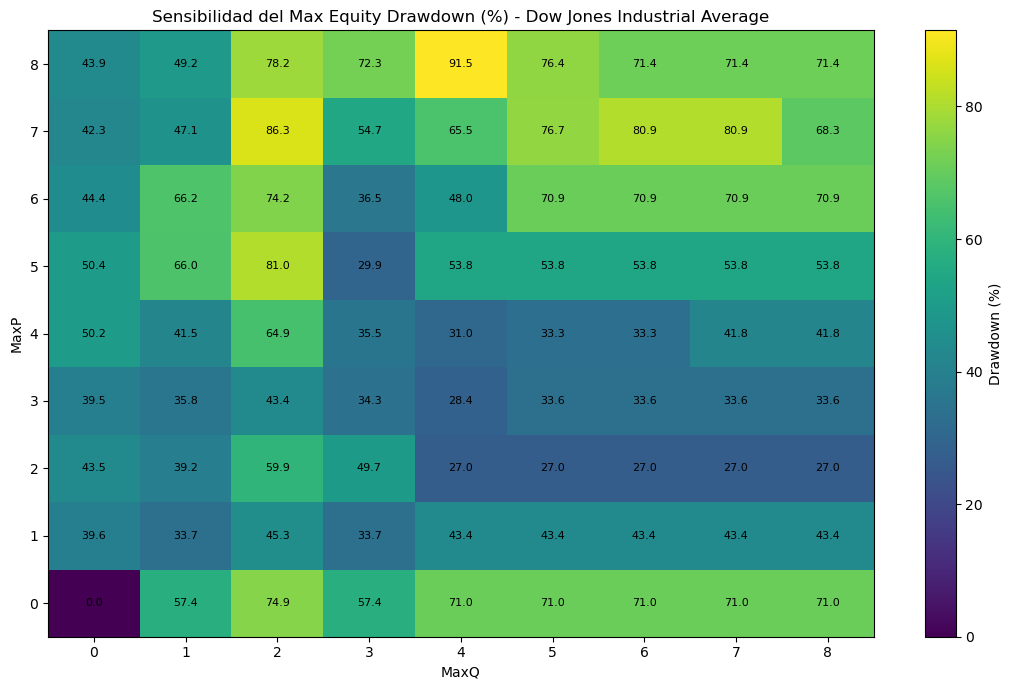

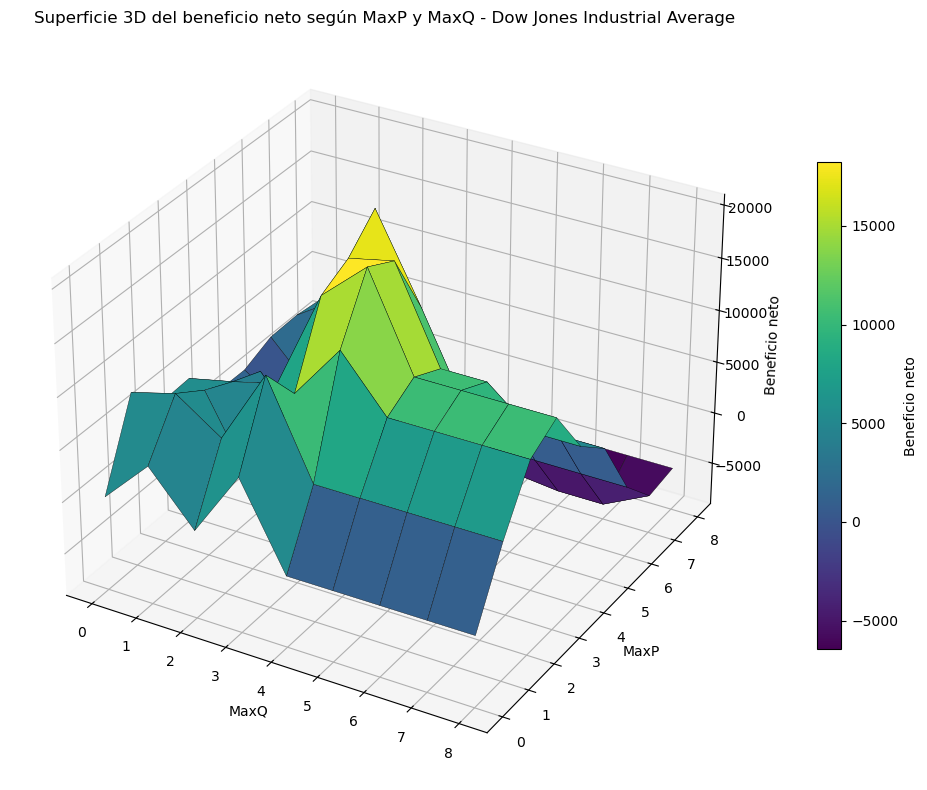

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

archivo = "Resultados.xlsx"  # Cambia por el nombre de tu archivo
hoja = 1                     # Primera hoja del Excel

df = pd.read_excel(archivo, sheet_name=hoja)

# Limpiar nombres de columnas y espacios repetidos
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("Columnas encontradas:")
print(df.columns.tolist())

# Verificar que existan las columnas necesarias
columnas = [
    "MaxP",
    "MaxQ",
    "Rentabilidad (%)",
    "Beneficio Neto",
    "Max equity drawdown (%)"
]

faltantes = [c for c in columnas if c not in df.columns]

if faltantes:
    raise ValueError(
        f"Faltan estas columnas en el Excel: {faltantes}"
    )

# Convertir las variables a formato numérico
def convertir_numero(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(serie, errors="coerce")

    s = serie.astype(str).str.strip()
    s = s.str.replace("%", "", regex=False)
    s = s.str.replace(" ", "", regex=False)

    # Admite formatos como 1.234,56 y 1234,56
    formato_espanol = s.str.contains(",", regex=False)

    s.loc[formato_espanol] = (
        s.loc[formato_espanol]
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )

    return pd.to_numeric(s, errors="coerce")


for col in columnas:
    df[col] = convertir_numero(df[col])

# Crear matrices MaxP x MaxQ
roi = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Rentabilidad (%)", aggfunc="mean"
).sort_index().sort_index(axis=1)

drawdown = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Max equity drawdown (%)", aggfunc="mean"
).reindex(index=roi.index, columns=roi.columns)

beneficio = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Beneficio Neto", aggfunc="mean"
).reindex(index=roi.index, columns=roi.columns)

# ============================================================
# 2. GRÁFICO 1: MAPA DE CALOR DE RENTABILIDAD
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

im = ax.imshow(
    roi.to_numpy(),
    aspect="auto",
    origin="lower"
)

ax.set_xticks(range(len(roi.columns)))
ax.set_xticklabels(roi.columns)
ax.set_yticks(range(len(roi.index)))
ax.set_yticklabels(roi.index)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_title("Sensibilidad de la rentabilidad (%) - Dow Jones Industrial Average")

for i in range(len(roi.index)):
    for j in range(len(roi.columns)):
        valor = roi.iloc[i, j]
        if pd.notna(valor):
            ax.text(
                j, i, f"{valor:.1f}",
                ha="center", va="center", fontsize=8
            )

fig.colorbar(im, ax=ax, label="Rentabilidad (%)")
plt.tight_layout()
plt.show()

# ============================================================
# 3. GRÁFICO 2: MAPA DE CALOR DEL DRAWDOWN
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

im = ax.imshow(
    drawdown.to_numpy(),
    aspect="auto",
    origin="lower"
)

ax.set_xticks(range(len(drawdown.columns)))
ax.set_xticklabels(drawdown.columns)
ax.set_yticks(range(len(drawdown.index)))
ax.set_yticklabels(drawdown.index)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_title("Sensibilidad del Max Equity Drawdown (%) - Dow Jones Industrial Average")

for i in range(len(drawdown.index)):
    for j in range(len(drawdown.columns)):
        valor = drawdown.iloc[i, j]
        if pd.notna(valor):
            ax.text(
                j, i, f"{valor:.1f}",
                ha="center", va="center", fontsize=8
            )

fig.colorbar(im, ax=ax, label="Drawdown (%)")
plt.tight_layout()
plt.show()

# ============================================================
# 5. GRÁFICO 4: SUPERFICIE 3D DEL BENEFICIO NETO
# ============================================================

from mpl_toolkits.mplot3d import Axes3D

X, Y = np.meshgrid(
    beneficio.columns.to_numpy(dtype=float),
    beneficio.index.to_numpy(dtype=float)
)

Z = beneficio.to_numpy(dtype=float)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.25,
    antialiased=True
)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_zlabel("Beneficio neto")
ax.set_title("Superficie 3D del beneficio neto según MaxP y MaxQ - Dow Jones Industrial Average")

fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    label="Beneficio neto"
)

plt.tight_layout()
plt.show()


Columnas encontradas:
['MaxP', 'MaxQ', 'Activo', 'Rentabilidad (%)', 'Beneficio Neto', 'Max equity drawdown (%)']


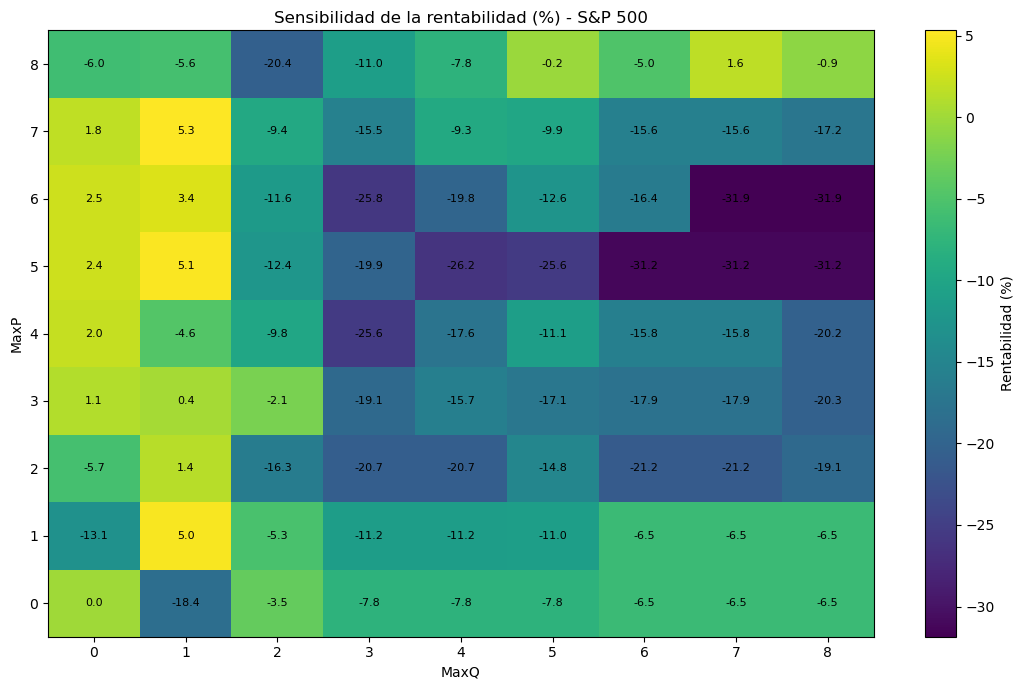

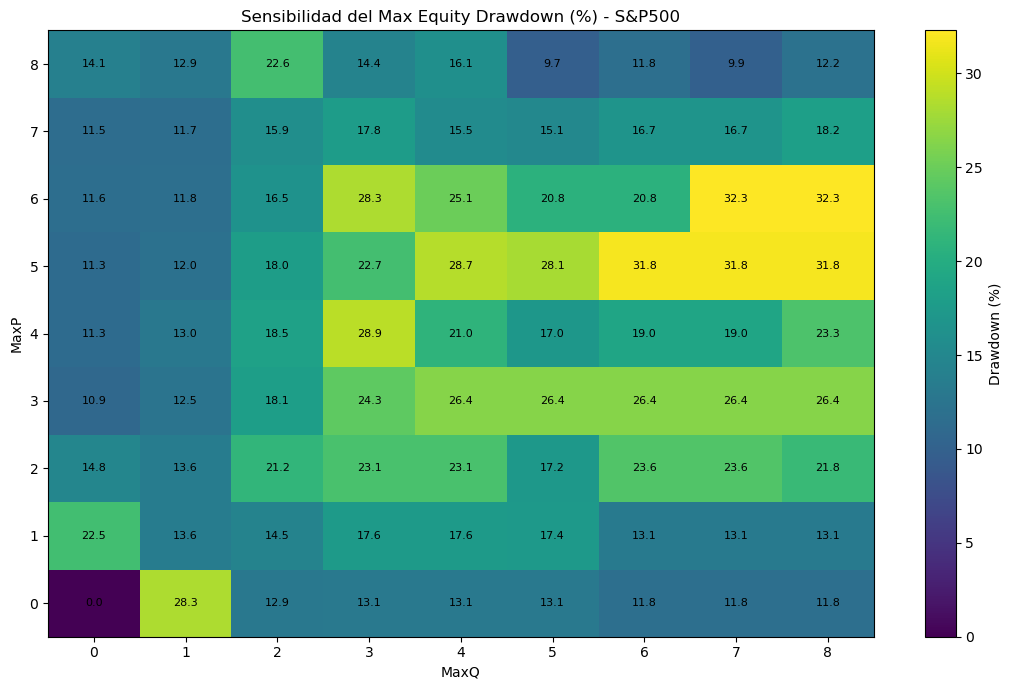

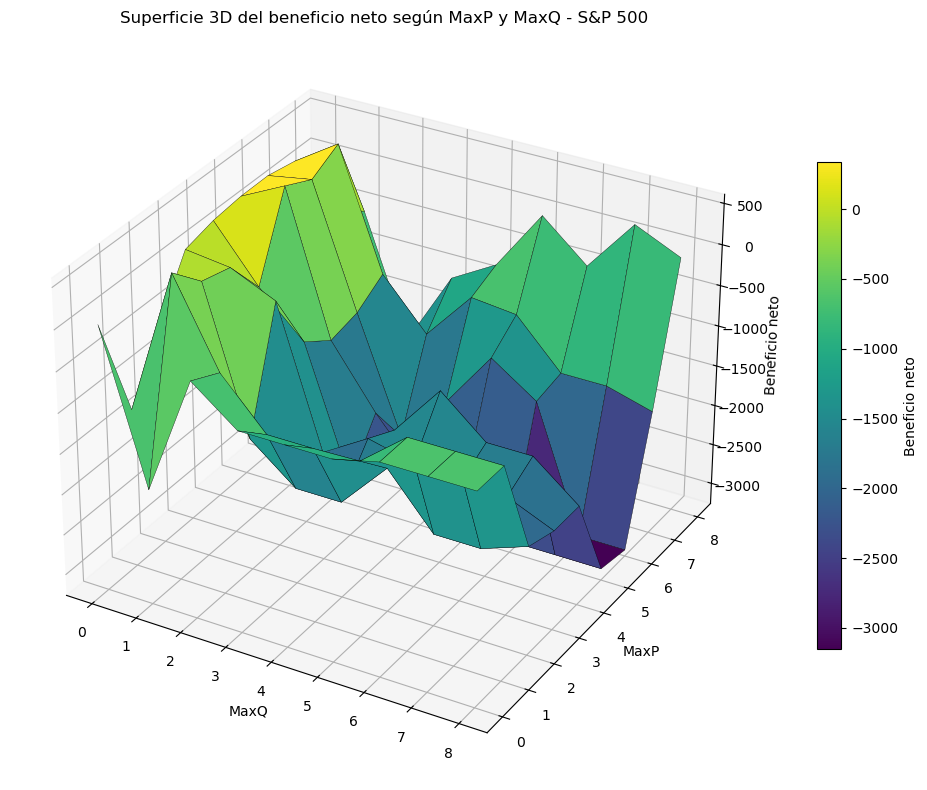

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

archivo = "Resultados.xlsx"  # Cambia por el nombre de tu archivo
hoja = 2                     

df = pd.read_excel(archivo, sheet_name=hoja)

# Limpiar nombres de columnas y espacios repetidos
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("Columnas encontradas:")
print(df.columns.tolist())

# Verificar que existan las columnas necesarias
columnas = [
    "MaxP",
    "MaxQ",
    "Rentabilidad (%)",
    "Beneficio Neto",
    "Max equity drawdown (%)"
]

faltantes = [c for c in columnas if c not in df.columns]

if faltantes:
    raise ValueError(
        f"Faltan estas columnas en el Excel: {faltantes}"
    )

# Convertir las variables a formato numérico
def convertir_numero(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(serie, errors="coerce")

    s = serie.astype(str).str.strip()
    s = s.str.replace("%", "", regex=False)
    s = s.str.replace(" ", "", regex=False)

    # Admite formatos como 1.234,56 y 1234,56
    formato_espanol = s.str.contains(",", regex=False)

    s.loc[formato_espanol] = (
        s.loc[formato_espanol]
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )

    return pd.to_numeric(s, errors="coerce")


for col in columnas:
    df[col] = convertir_numero(df[col])

# Crear matrices MaxP x MaxQ
roi = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Rentabilidad (%)", aggfunc="mean"
).sort_index().sort_index(axis=1)

drawdown = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Max equity drawdown (%)", aggfunc="mean"
).reindex(index=roi.index, columns=roi.columns)

beneficio = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Beneficio Neto", aggfunc="mean"
).reindex(index=roi.index, columns=roi.columns)

# ============================================================
# 2. GRÁFICO 1: MAPA DE CALOR DE RENTABILIDAD
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

im = ax.imshow(
    roi.to_numpy(),
    aspect="auto",
    origin="lower"
)

ax.set_xticks(range(len(roi.columns)))
ax.set_xticklabels(roi.columns)
ax.set_yticks(range(len(roi.index)))
ax.set_yticklabels(roi.index)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_title("Sensibilidad de la rentabilidad (%) - S&P 500")

for i in range(len(roi.index)):
    for j in range(len(roi.columns)):
        valor = roi.iloc[i, j]
        if pd.notna(valor):
            ax.text(
                j, i, f"{valor:.1f}",
                ha="center", va="center", fontsize=8
            )

fig.colorbar(im, ax=ax, label="Rentabilidad (%)")
plt.tight_layout()
plt.show()

# ============================================================
# 3. GRÁFICO 2: MAPA DE CALOR DEL DRAWDOWN
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

im = ax.imshow(
    drawdown.to_numpy(),
    aspect="auto",
    origin="lower"
)

ax.set_xticks(range(len(drawdown.columns)))
ax.set_xticklabels(drawdown.columns)
ax.set_yticks(range(len(drawdown.index)))
ax.set_yticklabels(drawdown.index)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_title("Sensibilidad del Max Equity Drawdown (%) - S&P500")

for i in range(len(drawdown.index)):
    for j in range(len(drawdown.columns)):
        valor = drawdown.iloc[i, j]
        if pd.notna(valor):
            ax.text(
                j, i, f"{valor:.1f}",
                ha="center", va="center", fontsize=8
            )

fig.colorbar(im, ax=ax, label="Drawdown (%)")
plt.tight_layout()
plt.show()

# ============================================================
# 5. GRÁFICO 4: SUPERFICIE 3D DEL BENEFICIO NETO
# ============================================================

from mpl_toolkits.mplot3d import Axes3D

X, Y = np.meshgrid(
    beneficio.columns.to_numpy(dtype=float),
    beneficio.index.to_numpy(dtype=float)
)

Z = beneficio.to_numpy(dtype=float)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.25,
    antialiased=True
)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_zlabel("Beneficio neto")
ax.set_title("Superficie 3D del beneficio neto según MaxP y MaxQ - S&P 500")

fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    label="Beneficio neto"
)

plt.tight_layout()
plt.show()


Columnas encontradas:
['MaxP', 'MaxQ', 'Activo', 'Rentabilidad (%)', 'Beneficio Neto', 'Max equity drawdown (%)']


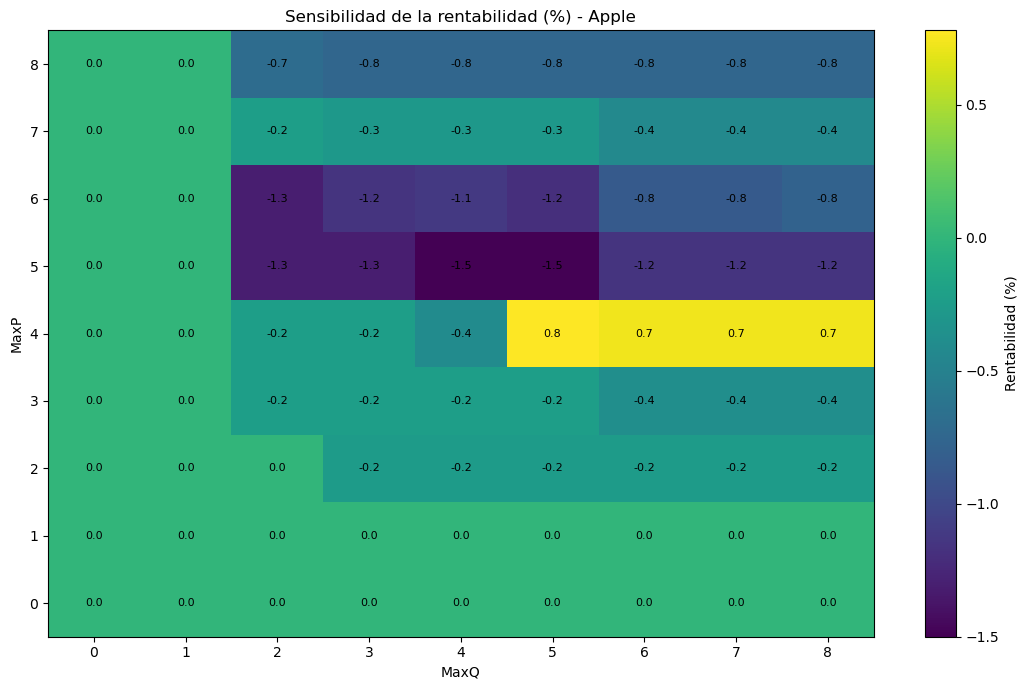

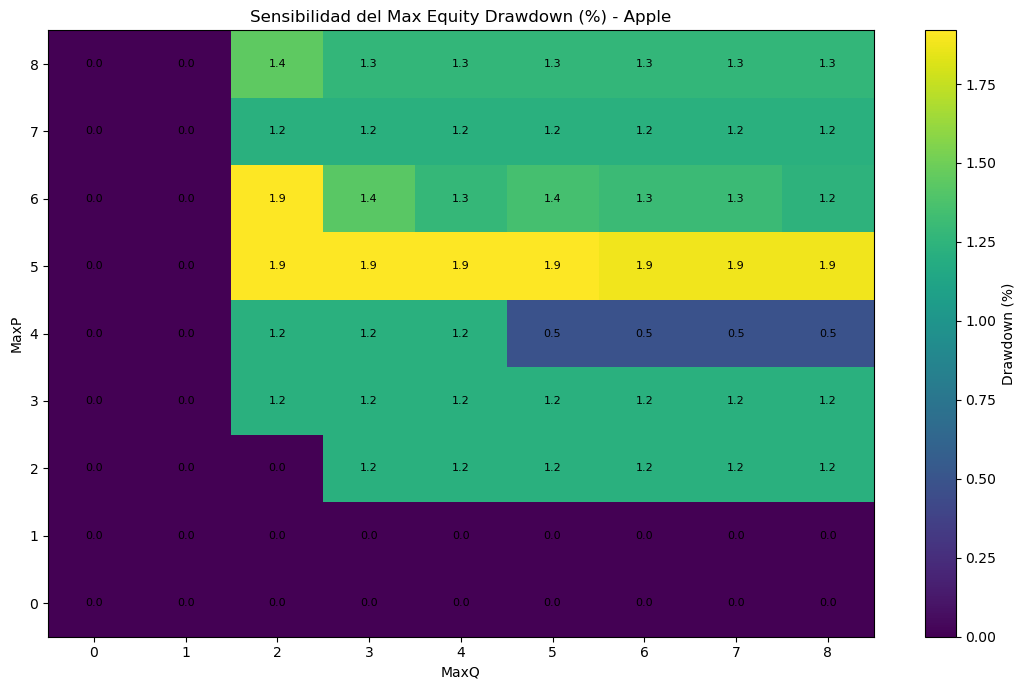

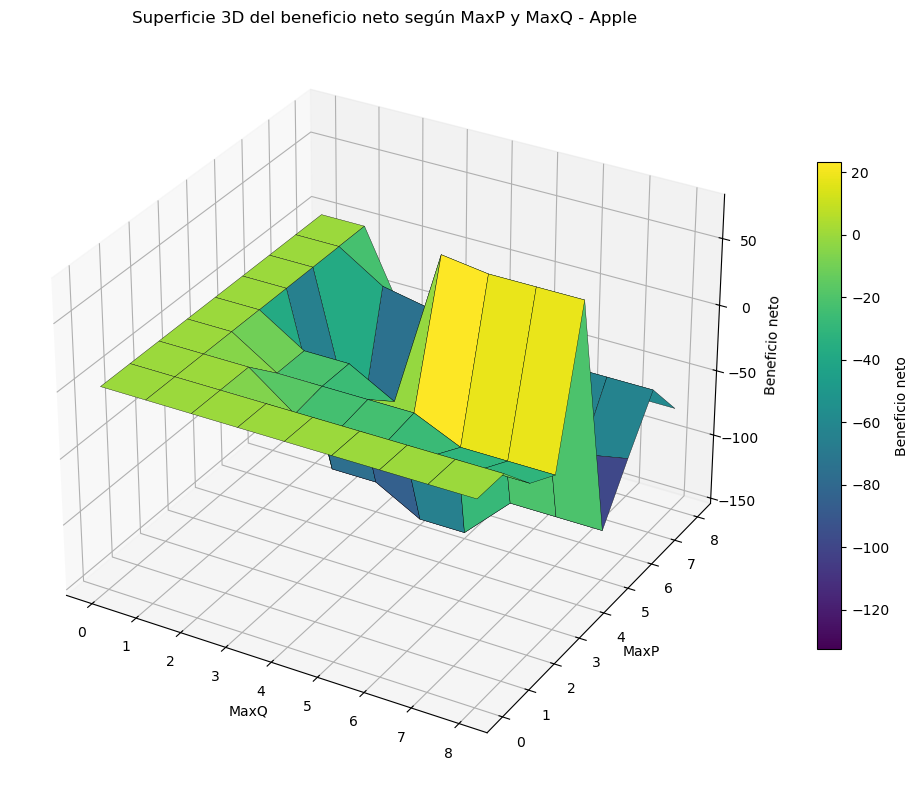

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

archivo = "Resultados.xlsx"  # Cambia por el nombre de tu archivo
hoja = 3                     

df = pd.read_excel(archivo, sheet_name=hoja)

# Limpiar nombres de columnas y espacios repetidos
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("Columnas encontradas:")
print(df.columns.tolist())

# Verificar que existan las columnas necesarias
columnas = [
    "MaxP",
    "MaxQ",
    "Rentabilidad (%)",
    "Beneficio Neto",
    "Max equity drawdown (%)"
]

faltantes = [c for c in columnas if c not in df.columns]

if faltantes:
    raise ValueError(
        f"Faltan estas columnas en el Excel: {faltantes}"
    )

# Convertir las variables a formato numérico
def convertir_numero(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(serie, errors="coerce")

    s = serie.astype(str).str.strip()
    s = s.str.replace("%", "", regex=False)
    s = s.str.replace(" ", "", regex=False)

    # Admite formatos como 1.234,56 y 1234,56
    formato_espanol = s.str.contains(",", regex=False)

    s.loc[formato_espanol] = (
        s.loc[formato_espanol]
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )

    return pd.to_numeric(s, errors="coerce")


for col in columnas:
    df[col] = convertir_numero(df[col])

# Crear matrices MaxP x MaxQ
roi = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Rentabilidad (%)", aggfunc="mean"
).sort_index().sort_index(axis=1)

drawdown = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Max equity drawdown (%)", aggfunc="mean"
).reindex(index=roi.index, columns=roi.columns)

beneficio = df.pivot_table(
    index="MaxP", columns="MaxQ",
    values="Beneficio Neto", aggfunc="mean"
).reindex(index=roi.index, columns=roi.columns)

# ============================================================
# 2. GRÁFICO 1: MAPA DE CALOR DE RENTABILIDAD
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

im = ax.imshow(
    roi.to_numpy(),
    aspect="auto",
    origin="lower"
)

ax.set_xticks(range(len(roi.columns)))
ax.set_xticklabels(roi.columns)
ax.set_yticks(range(len(roi.index)))
ax.set_yticklabels(roi.index)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_title("Sensibilidad de la rentabilidad (%) - Apple")

for i in range(len(roi.index)):
    for j in range(len(roi.columns)):
        valor = roi.iloc[i, j]
        if pd.notna(valor):
            ax.text(
                j, i, f"{valor:.1f}",
                ha="center", va="center", fontsize=8
            )

fig.colorbar(im, ax=ax, label="Rentabilidad (%)")
plt.tight_layout()
plt.show()

# ============================================================
# 3. GRÁFICO 2: MAPA DE CALOR DEL DRAWDOWN
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

im = ax.imshow(
    drawdown.to_numpy(),
    aspect="auto",
    origin="lower"
)

ax.set_xticks(range(len(drawdown.columns)))
ax.set_xticklabels(drawdown.columns)
ax.set_yticks(range(len(drawdown.index)))
ax.set_yticklabels(drawdown.index)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_title("Sensibilidad del Max Equity Drawdown (%) - Apple")

for i in range(len(drawdown.index)):
    for j in range(len(drawdown.columns)):
        valor = drawdown.iloc[i, j]
        if pd.notna(valor):
            ax.text(
                j, i, f"{valor:.1f}",
                ha="center", va="center", fontsize=8
            )

fig.colorbar(im, ax=ax, label="Drawdown (%)")
plt.tight_layout()
plt.show()

# ============================================================
# 5. GRÁFICO 4: SUPERFICIE 3D DEL BENEFICIO NETO
# ============================================================

from mpl_toolkits.mplot3d import Axes3D

X, Y = np.meshgrid(
    beneficio.columns.to_numpy(dtype=float),
    beneficio.index.to_numpy(dtype=float)
)

Z = beneficio.to_numpy(dtype=float)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.25,
    antialiased=True
)

ax.set_xlabel("MaxQ")
ax.set_ylabel("MaxP")
ax.set_zlabel("Beneficio neto")
ax.set_title("Superficie 3D del beneficio neto según MaxP y MaxQ - Apple")

fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    label="Beneficio neto"
)

plt.tight_layout()
plt.show()
